In [1]:
from easySCFpy import loadH5
import scanpy as sc
import anndata as ad
from collections import Counter
import pandas as pd
import numpy as np
import gc

# DEG

In [3]:
epi = sc.read_h5ad("E:/Projects/BRCA/Intermediate_Data/ST/epi_objects_unified/epi_metacell.h5ad")

In [9]:
sc.pp.normalize_total(epi, target_sum=1e4)
sc.pp.log1p(epi)

## DCIS vs IDC

In [197]:
epi_filtered = epi[epi.obs['region'].isin(['DCIS','IDC'])]

In [198]:
Counter(epi_filtered.obs['clinical_subtype'])

Counter({'HR+': 79032, 'HER2+': 60071, 'TNBC': 47029})

In [244]:
Counter(epi_filtered.obs['clinical_subtype2'])

Counter({'HR+': 79032, 'TNBC': 47029, 'HER2+': 46768, 'HR+HER2+': 13303})

### HR+

In [ ]:
hr = epi_filtered[epi_filtered.obs['clinical_subtype2'] == "HR+"]

In [200]:
sc.tl.rank_genes_groups(hr, "region", method="wilcoxon")

d:\software\anaconda3\envs\stardist\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:640: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}


In [201]:
deg_dcis_df  = sc.get.rank_genes_groups_df(hr, group='DCIS')

In [202]:
deg_dcis_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/HR+_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [203]:
top_genes_dcis = pd.DataFrame(deg_dcis_df.loc[0:200, 'names'])

In [204]:
top_genes_dcis.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_HR+_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [205]:
deg_idc_df  = sc.get.rank_genes_groups_df(hr, group='IDC')

In [206]:
deg_idc_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/HR+_IDC_vs_DCIS_metacell_deg.csv', index=False)

In [207]:
top_genes_idc = pd.DataFrame(deg_idc_df.loc[0:200, 'names'])

In [208]:
top_genes_idc.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_HR+_IDC_vs_DCIS_metacell_deg.csv', index=False)

### HER2+

In [ ]:
her2 = epi_filtered[epi_filtered.obs['clinical_subtype2'] == "HER2+"]

In [210]:
sc.tl.rank_genes_groups(her2, "region", method="wilcoxon")

d:\software\anaconda3\envs\stardist\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:640: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}


In [211]:
deg_dcis_df  = sc.get.rank_genes_groups_df(her2, group='DCIS')

In [212]:
deg_dcis_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/HER2+_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [213]:
top_genes_dcis = pd.DataFrame(deg_dcis_df.loc[0:200, 'names'])

In [214]:
top_genes_dcis.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_HER2+_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [215]:
deg_idc_df  = sc.get.rank_genes_groups_df(hr, group='IDC')

In [216]:
deg_idc_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/HER2+_IDC_vs_DCIS_metacell_deg.csv', index=False)

In [217]:
top_genes_idc = pd.DataFrame(deg_idc_df.loc[0:200, 'names'])

In [218]:
top_genes_idc.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_HER2+_IDC_vs_DCIS_metacell_deg.csv', index=False)

### TNBC

In [ ]:
tnbc = epi_filtered[epi_filtered.obs['clinical_subtype2'] == "TNBC"]

In [220]:
sc.tl.rank_genes_groups(tnbc, "region", method="wilcoxon")

d:\software\anaconda3\envs\stardist\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:640: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}


In [221]:
deg_dcis_df  = sc.get.rank_genes_groups_df(tnbc, group='DCIS')

In [222]:
deg_dcis_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/TNBC_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [223]:
top_genes_dcis = pd.DataFrame(deg_dcis_df.loc[0:200, 'names'])

In [224]:
top_genes_dcis.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_TNBC_DCIS_vs_IDC_metacell_deg.csv', index=False)

In [225]:
deg_idc_df  = sc.get.rank_genes_groups_df(hr, group='IDC')

In [226]:
deg_idc_df.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/TNBC_IDC_vs_DCIS_metacell_deg.csv', index=False)

In [227]:
top_genes_idc = pd.DataFrame(deg_idc_df.loc[0:200, 'names'])

In [228]:
top_genes_idc.to_csv('E:/Projects/BRCA/results/ST/deg/clinical_subtype_version/top_TNBC_IDC_vs_DCIS_metacell_deg.csv', index=False)

# Meta cell clustering

In [3]:
epi = sc.read_h5ad("E:/Projects/BRCA/Intermediate_Data/ST/epi_objects_unified/epi_metacell.h5ad")

In [6]:
sc.pp.calculate_qc_metrics(epi, inplace=True)

In [7]:
epi_raw = epi.copy()

In [8]:
sc.pp.normalize_total(epi, target_sum=1e4)
sc.pp.log1p(epi)

In [9]:
sc.pp.highly_variable_genes(epi, min_mean=0.0125, max_mean=3, min_disp=0.5)

In [10]:
epi_filtered = epi[:, epi.var.highly_variable]
epi_filtered.raw = epi_filtered.copy()

sc.pp.regress_out(epi_filtered, ["total_counts"])
sc.pp.scale(epi_filtered, max_value=10)

sc.tl.pca(epi_filtered, svd_solver="arpack")

sc.pp.neighbors(epi_filtered, n_neighbors=10, n_pcs=30)
sc.tl.umap(epi_filtered)
sc.tl.louvain(epi_filtered, resolution=1)

d:\software\anaconda3\envs\stardist\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Axes: title={'center': 'Epithelial'}, xlabel='UMAP1', ylabel='UMAP2'>

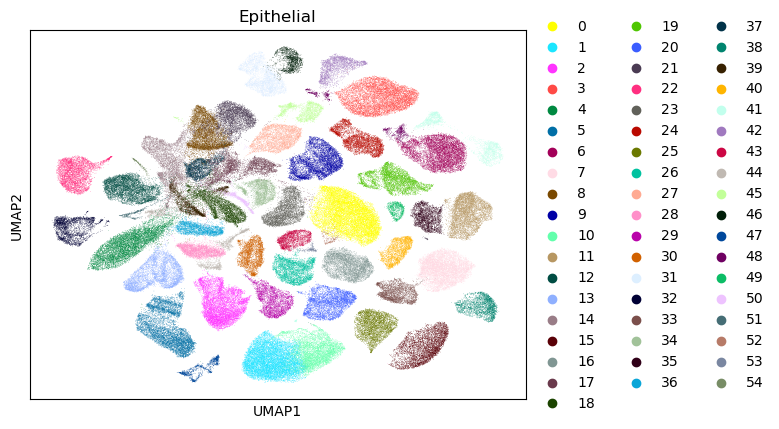

In [12]:
sc.pl.umap(epi_filtered, color = "louvain", title = 'Epithelial', show=False)

<Axes: title={'center': 'Epithelial'}, xlabel='UMAP1', ylabel='UMAP2'>

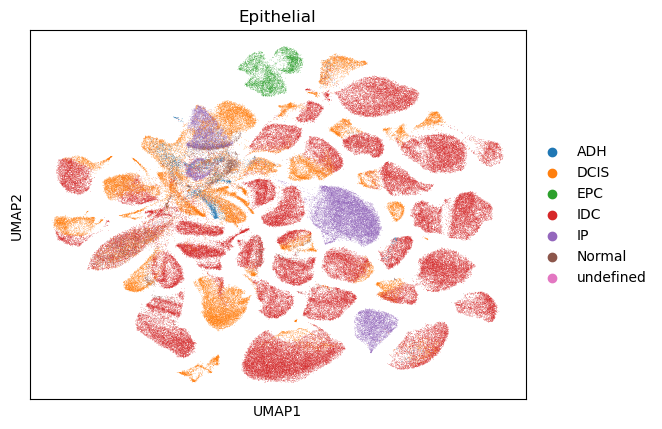

In [53]:
sc.pl.umap(epi_filtered, color = "region", title = 'Epithelial', show=False)